# CART Algorithm Using Python

**Dataset:** Breast Cancer Wisconsin Diagnostic dataset (built into scikit-learn)  
**Task:** Binary classification — predict whether a tumor is malignant or benign.  
**Algorithm:** Classification and Regression Trees (CART), implemented with `DecisionTreeClassifier`.

CART builds binary decision trees. For classification, this implementation uses **Gini impurity** to choose splits.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

## 2. Load the dataset

In [2]:
# Load the dataset directly from scikit-learn
dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset shape:", X.shape)
print("Target classes:", dict(enumerate(dataset.target_names)))
display(X.head())

Dataset shape: (569, 30)
Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Explore the data

In [3]:
print("Missing values:", X.isnull().sum().sum())
print("\\nClass distribution:")
print(y.map(dict(enumerate(dataset.target_names))).value_counts())

display(X.describe().T.head())

Missing values: 0
\nClass distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634


## 4. Split into training and testing sets

We keep 20% of the records for testing. `stratify=y` preserves the class proportions in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 455
Testing records: 114


## 5. Train the CART model

`criterion="gini"` uses Gini impurity to evaluate candidate splits.  
`max_depth=4` limits tree depth to reduce overfitting.  
`random_state=42` makes the result reproducible.

In [5]:
cart_model = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

cart_model.fit(X_train, y_train)

print("CART model training completed.")

CART model training completed.


## 6. Make predictions

In [6]:
y_pred = cart_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
display(results.head(10))

,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,1
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


## 7. Evaluate the model

Accuracy: 0.9386 (93.86%)
\nClassification report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



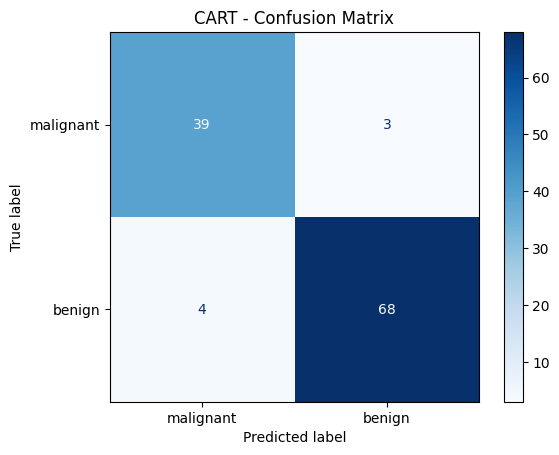

In [7]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=dataset.target_names
))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)
disp.plot(cmap="Blues")
plt.title("CART - Confusion Matrix")
plt.show()

## 8. Visualize the decision tree

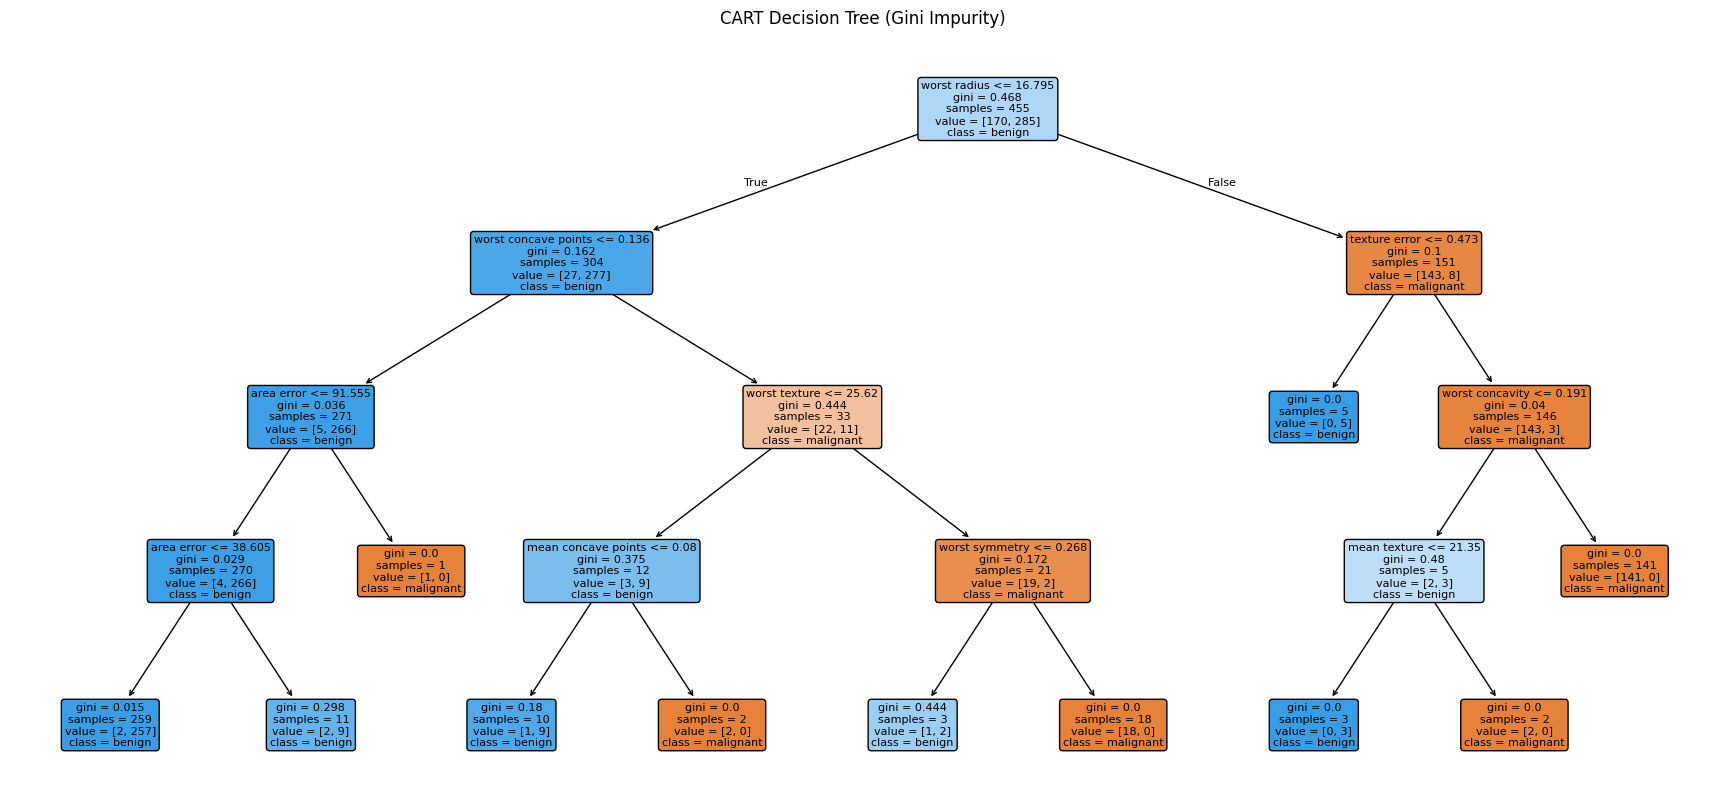

In [8]:
plt.figure(figsize=(22, 10))
plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=dataset.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree (Gini Impurity)")
plt.show()

## 9. Feature importance

,Importance
worst radius,0.733548
worst concave points,0.122028
texture error,0.045785
worst texture,0.032319
worst concavity,0.017161
mean concave points,0.013327
area error,0.012704
mean texture,0.011846
worst symmetry,0.011282
mean area,0.000000


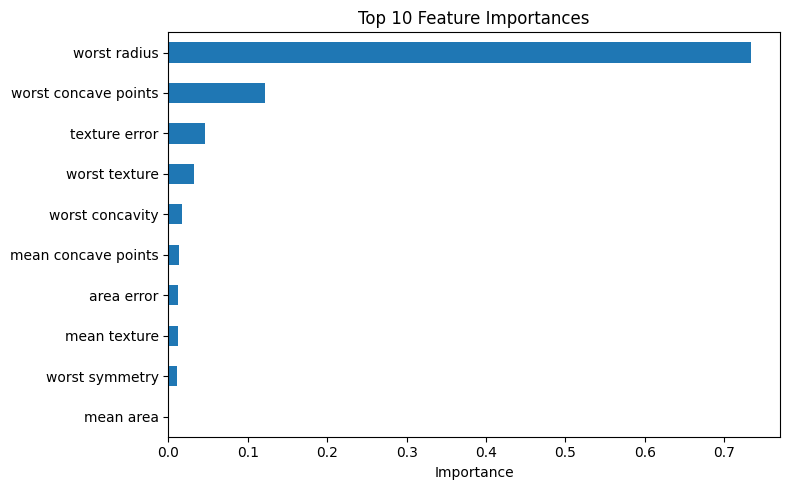

In [9]:
importance = pd.Series(
    cart_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance.head(10).to_frame("Importance"))

importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Feature Importances"
)
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Business insights

The results can inform how a screening-support workflow might be evaluated, but they do **not** establish that the model is ready for clinical use.

- **Prioritize missed malignant cases:** Review the confusion matrix summary below. A malignant case predicted as benign is the most consequential error to investigate; accuracy alone can hide this risk.
- **Plan for follow-up workload:** Benign cases predicted as malignant can lead to additional reviews or tests. Any pilot should measure this workload alongside missed-case rates.
- **Use feature importance for investigation, not causation:** The tree's leading feature can help guide data-quality checks and clinical review, but importance is model-specific and does not show that a feature causes an outcome.
- **Before deployment:** Validate on representative external data, assess performance across relevant patient groups, and have qualified clinicians oversee decisions. This teaching dataset and single train/test split are not sufficient for deployment decisions.

In [ ]:
# The confusion matrix uses dataset target order: malignant (0), then benign (1).
malignant_support = int(cm[0].sum())
malignant_predicted_benign = int(cm[0, 1])
benign_predicted_malignant = int(cm[1, 0])

business_summary = pd.DataFrame({
    "Measure": [
        "Test-set accuracy",
        "Malignant cases predicted benign",
        "Benign cases predicted malignant",
        "Malignant recall"
    ],
    "Result": [
        f"{accuracy:.1%}",
        f"{malignant_predicted_benign} of {malignant_support}",
        f"{benign_predicted_malignant} of {int(cm[1].sum())}",
        f"{cm[0, 0] / malignant_support:.1%}"
    ]
})
display(business_summary)

top_feature = importance.index[0]
print(f"Most influential feature in this fitted tree: {top_feature} "
      f"({importance.iloc[0]:.1%} of total impurity-based importance)")

## 11. Predict for a new sample

The example below uses the first test record. The model predicts its class and displays the corresponding label.

In [10]:
sample = X_test.iloc[[0]]
prediction = cart_model.predict(sample)[0]

print("Predicted class:", dataset.target_names[prediction])
print("Actual class:", dataset.target_names[y_test.iloc[0]])

Predicted class: malignant
Actual class: malignant


## 12. Conclusion

- CART was implemented using `DecisionTreeClassifier`.
- Gini impurity was used to select the best binary splits.
- The model was trained and evaluated using a held-out test set.
- Business insights connect error types and feature importance to workflow considerations and deployment limitations.
- Accuracy, precision, recall, F1-score, and a confusion matrix were used for evaluation.
- The decision-tree plot shows the rules learned by the model.

**Note:** This is a learning exercise using the built-in Breast Cancer Wisconsin dataset. It is not a medical diagnostic tool.